# Param Controller Dataset Evaluation

This notebook validates the PPO controller dataset before training.

It loads the per-run files under:

- `gvns/datasets/param_controller/training`
- `gvns/datasets/param_controller/validation`

The files are stored one per instance run. In this project they are saved with a `.npz` extension, but the current exporter writes a pickled payload. This notebook handles both the pickled payload and a real NumPy `.npz` file.

The checks are deliberately strict:

- reward distribution
- feature scale
- feature correlations
- action balance
- redundant or dead features
- per-instance and per-run summaries

In [1]:
from __future__ import annotations

import os
import re
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

TRAIN_ROOT = Path("../../datasets/param_controller/training")
VAL_ROOT = Path("../../datasets/param_controller/validation")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

ZERO_VAR_STD = 1e-8
NEAR_ZERO_VAR_STD = 1e-4
HIGH_CORR_THRESHOLD = 0.95
STRONG_CORR_THRESHOLD = 0.85

FEATURE_COLS = None

## 1) File discovery and robust loading

Every file under the training and validation roots is loaded into a flat transition table.

The notebook keeps file-level metadata so we can still inspect:
- split,
- size,
- instance name,
- run id,
- file path.

This means we do not need to merge the raw files on disk first; the notebook can analyze them as a combined table while preserving provenance.

In [2]:
def discover_files(root: Path):
    if not root.exists():
        raise FileNotFoundError(f"Dataset folder not found: {root}")
    files = sorted(
        p for p in root.rglob("*")
        if p.is_file() and p.suffix.lower() in {".npz", ".pkl", ".pickle"}
    )
    if not files:
        raise ValueError(f"No dataset files found under {root}")
    return files

def parse_file_metadata(path: Path):
    parts = path.parts
    split = "unknown"
    size = "unknown"

    if "training" in parts:
        split = "training"
        idx = parts.index("training")
        if idx + 1 < len(parts):
            size = parts[idx + 1]
    elif "validation" in parts:
        split = "validation"
        idx = parts.index("validation")
        if idx + 1 < len(parts):
            size = parts[idx + 1]

    instance = path.stem
    run_id = "unknown"
    m = re.search(r"(.+)_run(\d+)$", path.stem)
    if m:
        instance = m.group(1)
        run_id = int(m.group(2))

    return {
        "split": split,
        "size": size,
        "instance": instance,
        "run_id": run_id,
        "file_name": path.name,
        "file_path": str(path),
    }

def load_dataset_file(path: Path):
    meta = parse_file_metadata(path)

    # Try pickle payload first (this is how OfflineDataset.save() currently writes files).
    try:
        with open(path, "rb") as f:
            payload = pickle.load(f)

        if isinstance(payload, dict) and "data" in payload and "feature_names" in payload:
            data = payload["data"]
            feature_names = list(payload["feature_names"])
            meta["format"] = "pickle_payload"
            meta["normalized"] = payload.get("normalized", False)

            states = np.asarray(data["states"], dtype=np.float32)
            actions = np.asarray(data["actions"], dtype=np.int64)
            rewards = np.asarray(data["rewards"], dtype=np.float32)
            next_states = np.asarray(data["next_states"], dtype=np.float32)
            dones = np.asarray(data["dones"], dtype=np.bool_)

            meta_block = data.get("meta", {})
            meta_arrays = {}
            if isinstance(meta_block, dict):
                for k, v in meta_block.items():
                    meta_arrays[k] = np.asarray(v)
            return feature_names, states, actions, rewards, next_states, dones, meta, meta_arrays
    except Exception:
        pass

    # Fallback: true npz archive.
    with np.load(path, allow_pickle=True) as npz:
        meta["format"] = "npz"
        meta["normalized"] = None
        feature_names = list(npz["feature_names"].tolist()) if "feature_names" in npz.files else None
        states = np.asarray(npz["states"], dtype=np.float32)
        actions = np.asarray(npz["actions"], dtype=np.int64)
        rewards = np.asarray(npz["rewards"], dtype=np.float32)
        next_states = np.asarray(npz["next_states"], dtype=np.float32)
        dones = np.asarray(npz["dones"], dtype=np.bool_)
        meta_arrays = {}
        if "meta" in npz.files:
            meta_raw = npz["meta"].item()
            if isinstance(meta_raw, dict):
                for k, v in meta_raw.items():
                    meta_arrays[k] = np.asarray(v)
        return feature_names, states, actions, rewards, next_states, dones, meta, meta_arrays

def build_transition_dataframe(root: Path):
    files = discover_files(root)
    dfs = []
    file_summaries = []
    feature_names_global = None

    for fp in files:
        feature_names, states, actions, rewards, next_states, dones, meta, meta_arrays = load_dataset_file(fp)

        if feature_names is not None:
            if feature_names_global is None:
                feature_names_global = feature_names
            elif feature_names != feature_names_global:
                raise ValueError(
                    f"Feature mismatch in file {fp}\n"
                    f"Expected: {feature_names_global}\n"
                    f"Got: {feature_names}"
                )

        if feature_names_global is None:
            raise ValueError(f"No feature_names found in {fp}")

        n = len(actions)
        if not (states.shape[0] == n == rewards.shape[0] == next_states.shape[0] == dones.shape[0]):
            raise ValueError(f"Length mismatch in file {fp}")

        df = pd.DataFrame(states, columns=feature_names_global)
        for i, name in enumerate(feature_names_global):
            df[f"next_{name}"] = next_states[:, i]

        df["action"] = actions
        df["reward"] = rewards
        df["done"] = dones.astype(int)

        for k, v in meta.items():
            df[k] = v

        for k, arr in meta_arrays.items():
            if len(arr) == n:
                df[f"meta_{k}"] = arr
            else:
                df[f"meta_{k}"] = [repr(x) for x in arr]

        df["trans_id"] = np.arange(n)
        dfs.append(df)

        # per-file summary
        counts = np.bincount(actions.astype(int), minlength=int(actions.max()) + 1)
        p = counts / counts.sum()
        action_entropy = float(-(np.where(p > 0, p * np.log(p), 0.0)).sum())

        file_summaries.append({
            "file": fp.name,
            "split": meta["split"],
            "size": meta["size"],
            "instance": meta["instance"],
            "run_id": meta["run_id"],
            "transitions": n,
            "reward_mean": float(np.mean(rewards)),
            "reward_std": float(np.std(rewards)),
            "reward_min": float(np.min(rewards)),
            "reward_max": float(np.max(rewards)),
            "action_entropy": action_entropy,
            "format": meta.get("format"),
            "normalized": meta.get("normalized"),
        })

    full_df = pd.concat(dfs, ignore_index=True)
    file_summary_df = pd.DataFrame(file_summaries)
    return full_df, file_summary_df, feature_names_global, files

## 2) Load the training and validation splits

We load the splits separately first. This lets us compare them before making any training decisions.

The resulting tables are:
- `train_df`
- `val_df`

Each row is one transition.

In [3]:
train_df, train_file_summary, FEATURE_COLS, train_files = build_transition_dataframe(TRAIN_ROOT)
val_df, val_file_summary, _, val_files = build_transition_dataframe(VAL_ROOT)

print("Training files:", len(train_files))
print("Validation files:", len(val_files))
print("Feature count:", len(FEATURE_COLS))
print("Training transitions:", len(train_df))
print("Validation transitions:", len(val_df))

Training files: 56
Validation files: 20
Feature count: 40
Training transitions: 148265
Validation transitions: 68997


In [4]:
display(train_file_summary.head())
display(val_file_summary.head())

,file,split,size,instance,run_id,transitions,reward_mean,reward_std,reward_min,reward_max,action_entropy,format,normalized
0,C101_100_10_run1.npz,training,100,C101_100_10,1,1335,0.057182,0.114252,-0.166573,0.831201,2.075620,pickle_payload,False
1,C105_100_10_run1.npz,training,100,C105_100_10,1,1339,0.059606,0.116831,-0.181372,0.633063,2.072847,pickle_payload,False
2,C106_100_10_run1.npz,training,100,C106_100_10,1,1278,0.066350,0.119660,-0.156441,1.000000,2.074919,pickle_payload,False
3,C108_100_10_run1.npz,training,100,C108_100_10,1,1301,0.079261,0.114604,-0.120991,0.909432,2.076924,pickle_payload,False
4,C201_100_10_run1.npz,training,100,C201_100_10,1,1160,0.078562,0.135162,-0.108187,1.000000,2.077163,pickle_payload,False


,file,split,size,instance,run_id,transitions,reward_mean,reward_std,reward_min,reward_max,action_entropy,format,normalized
0,C102_100_10_run1.npz,validation,100,C102_100_10,1,1145,0.066465,0.123141,-0.092517,1.000000,2.077262,pickle_payload,False
1,C109_100_10_run1.npz,validation,100,C109_100_10,1,1318,0.086728,0.120841,-0.106741,1.000000,2.077854,pickle_payload,False
2,C203_100_10_run1.npz,validation,100,C203_100_10,1,1196,0.078294,0.115983,-0.050000,1.000000,2.076159,pickle_payload,False
3,R102_100_10_run1.npz,validation,100,R102_100_10,1,1657,0.043310,0.097060,-0.067784,1.000000,2.075457,pickle_payload,False
4,R106_100_10_run1.npz,validation,100,R106_100_10,1,1322,0.047296,0.099019,-0.054129,0.410495,2.076139,pickle_payload,False


## 3) Global sanity checks

We verify:
- feature columns exist and are consistent,
- there are no NaNs or infinities,
- every instance/run produced data,
- done flags are visible,
- the split structure is intact.

In [5]:
def basic_sanity_checks(df: pd.DataFrame, name: str):
    print(f"\n=== {name.upper()} SANITY CHECKS ===")

    missing_cols = [c for c in FEATURE_COLS if c not in df.columns]
    print("Missing feature columns:", missing_cols)

    X = df[FEATURE_COLS].to_numpy(dtype=np.float64)
    print("NaNs in features:", int(np.isnan(X).sum()))
    print("Infs in features:", int(np.isinf(X).sum()))
    print("Reward NaNs:", int(df["reward"].isna().sum()))
    print("Action NaNs:", int(df["action"].isna().sum()))
    print("Done ratio:", float(df["done"].mean()))

    run_counts = df.groupby(["instance", "run_id"], dropna=False).size()
    print("Runs:", int(run_counts.shape[0]))
    print("Transitions per run:")
    display(run_counts.describe())

basic_sanity_checks(train_df, "training")
basic_sanity_checks(val_df, "validation")


=== TRAINING SANITY CHECKS ===
Missing feature columns: []
NaNs in features: 0
Infs in features: 0
Reward NaNs: 0
Action NaNs: 0
Done ratio: 0.0
Runs: 56
Transitions per run:


count      56.000000
mean     2647.589286
std      1315.954666
min      1130.000000
25%      1371.500000
50%      2464.500000
75%      3918.750000
max      4683.000000
dtype: float64


=== VALIDATION SANITY CHECKS ===
Missing feature columns: []
NaNs in features: 0
Infs in features: 0
Reward NaNs: 0
Action NaNs: 0
Done ratio: 0.0
Runs: 20
Transitions per run:


count      20.000000
mean     3449.850000
std      2165.479752
min      1145.000000
25%      1302.000000
50%      3221.000000
75%      5573.500000
max      6511.000000
dtype: float64

## 4) Reward distribution

The reward is the most important signal for PPO. We inspect it from several angles:

- overall distribution on train and validation,
- summary statistics,
- distribution by instance size,
- per-instance/run spread.

The reward should not be:
- exploding,
- completely flat,
- or almost constant.

It should have enough variance to let PPO distinguish good and bad decisions.

In [ ]:
def reward_summary(df: pd.DataFrame):
    return pd.Series({
        "count": len(df),
        "mean": df["reward"].mean(),
        "std": df["reward"].std(),
        "min": df["reward"].min(),
        "p01": df["reward"].quantile(0.01),
        "p05": df["reward"].quantile(0.05),
        "median": df["reward"].median(),
        "p95": df["reward"].quantile(0.95),
        "p99": df["reward"].quantile(0.99),
        "max": df["reward"].max(),
    })

reward_split_summary = pd.DataFrame({
    "training": reward_summary(train_df),
    "validation": reward_summary(val_df),
}).T

display(reward_split_summary)

,count,mean,std,min,p01,p05,median,p95,p99,max
training,148265.0,0.073513,0.120979,-0.407063,-0.055122,-0.05,0.067090,0.232551,0.376739,1.0
validation,68997.0,0.064622,0.117970,-0.365795,-0.072951,-0.05,0.054097,0.222033,0.345069,1.0


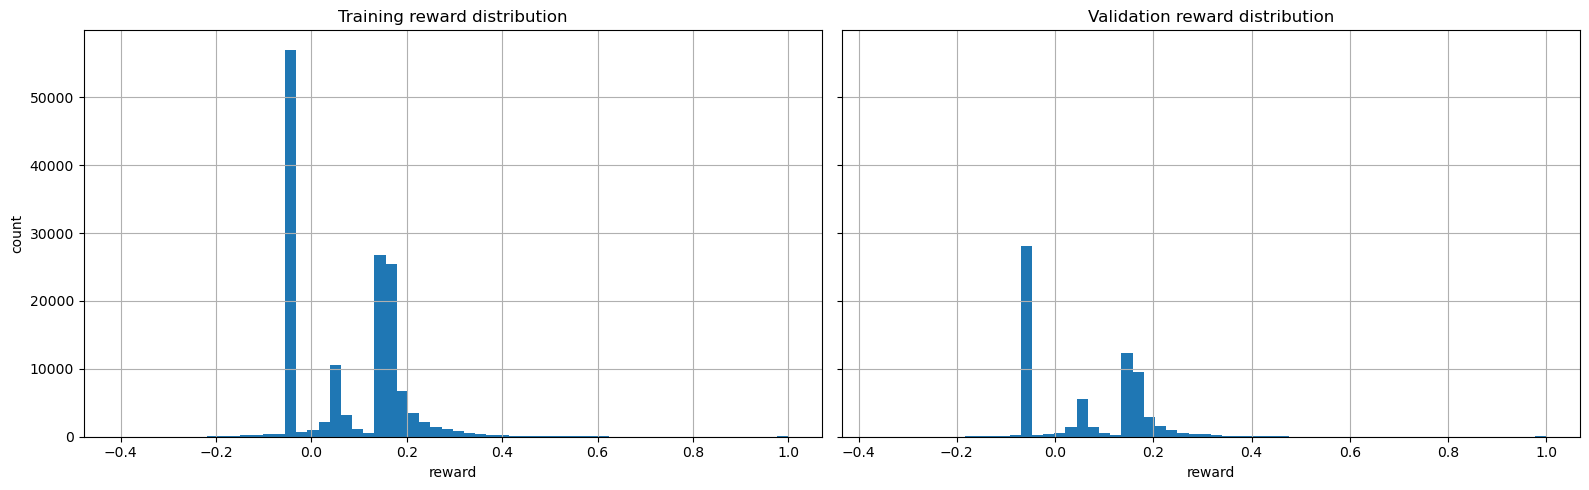

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
axes[0].hist(train_df["reward"], bins=60)
axes[0].set_title("Training reward distribution")
axes[0].set_xlabel("reward")
axes[0].set_ylabel("count")

axes[1].hist(val_df["reward"], bins=60)
axes[1].set_title("Validation reward distribution")
axes[1].set_xlabel("reward")

plt.tight_layout()
plt.show()

In [8]:
reward_by_size = (
    pd.concat([
        train_df[["size", "reward"]].assign(split="training"),
        val_df[["size", "reward"]].assign(split="validation"),
    ], ignore_index=True)
    .groupby(["split", "size"])["reward"]
    .agg(["count", "mean", "std", "min", "median", "max"])
    .reset_index()
)
display(reward_by_size)

,split,size,count,mean,std,min,median,max
0,training,100,38531,0.069197,0.108528,-0.181372,0.150060,1.0
1,training,50,109734,0.075029,0.125022,-0.407063,0.063334,1.0
2,validation,100,13657,0.061692,0.106826,-0.106741,0.054483,1.0
3,validation,50,55340,0.065345,0.120551,-0.365795,0.054034,1.0


C:\Users\HP\AppData\Local\Temp\ipykernel_19072\838732417.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(plot_data, labels=labels, showfliers=False)


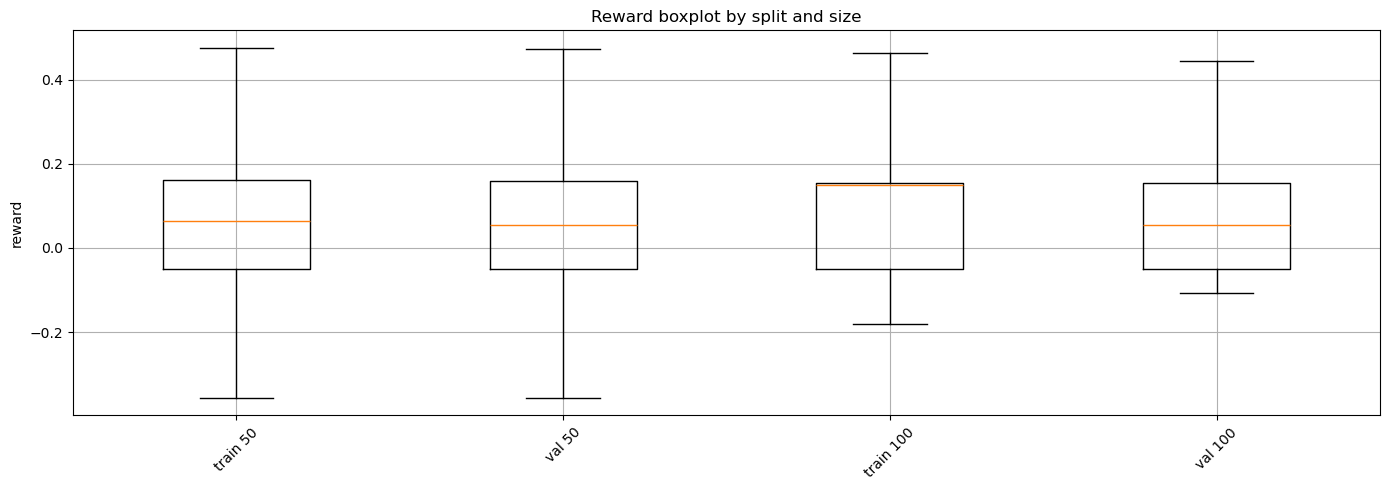

In [9]:
fig, ax = plt.subplots(figsize=(14, 5))
sizes = sorted(set(train_df["size"].astype(str)).union(set(val_df["size"].astype(str))), key=lambda x: int(x))
plot_data = []
labels = []

for s in sizes:
    tr = train_df.loc[train_df["size"].astype(str) == s, "reward"].values
    va = val_df.loc[val_df["size"].astype(str) == s, "reward"].values
    if len(tr):
        plot_data.append(tr)
        labels.append(f"train {s}")
    if len(va):
        plot_data.append(va)
        labels.append(f"val {s}")

ax.boxplot(plot_data, labels=labels, showfliers=False)
ax.set_title("Reward boxplot by split and size")
ax.set_ylabel("reward")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 5) Action balance

Because data collection used a random policy, action counts should be reasonably balanced.

We inspect:
- action counts,
- action percentages,
- entropy of the action distribution,
- balance by size,
- balance by split.

If one action is missing or very rare, the final PPO policy will be biased.

In [10]:
def action_balance_table(df: pd.DataFrame, title: str):
    counts = df["action"].value_counts().sort_index()
    total = len(df)
    table = pd.DataFrame({
        "count": counts,
        "pct": counts / total * 100.0,
    })
    print(f"\n=== {title} ACTION BALANCE ===")
    display(table)

    p = counts.values / counts.values.sum()
    entropy = float(-(np.where(p > 0, p * np.log(p), 0.0)).sum())
    print(f"Action entropy (nats): {entropy:.4f}")
    return table

train_action_table = action_balance_table(train_df, "Training")
val_action_table = action_balance_table(val_df, "Validation")


=== Training ACTION BALANCE ===


,count,pct
action,,
0,18580,12.531616
1,18708,12.617948
2,18482,12.465518
3,18642,12.573433
4,18156,12.245641
5,18328,12.361650
6,18647,12.576805
7,18722,12.627390


Action entropy (nats): 2.0794

=== Validation ACTION BALANCE ===


,count,pct
action,,
0,8636,12.516486
1,8573,12.425178
2,8542,12.380248
3,8693,12.599099
4,8690,12.594750
5,8587,12.445469
6,8601,12.465759
7,8675,12.573010


Action entropy (nats): 2.0794


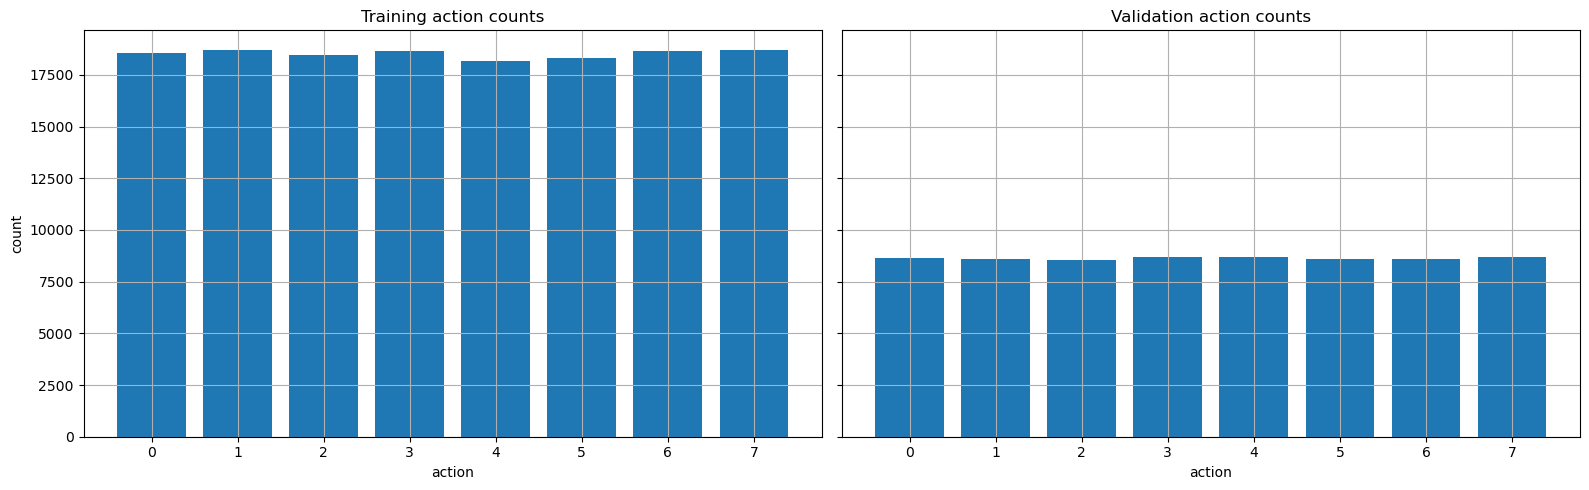

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

train_counts = train_df["action"].value_counts().sort_index()
val_counts = val_df["action"].value_counts().sort_index()

axes[0].bar(train_counts.index.astype(int), train_counts.values)
axes[0].set_title("Training action counts")
axes[0].set_xlabel("action")
axes[0].set_ylabel("count")

axes[1].bar(val_counts.index.astype(int), val_counts.values)
axes[1].set_title("Validation action counts")
axes[1].set_xlabel("action")

plt.tight_layout()
plt.show()

,split,size,action,count
0,training,100,0,4680
1,training,100,1,4857
2,training,100,2,4842
3,training,100,3,4903
4,training,100,4,4717
5,training,100,5,4820
6,training,100,6,4800
7,training,100,7,4912
8,training,50,0,13900
9,training,50,1,13851


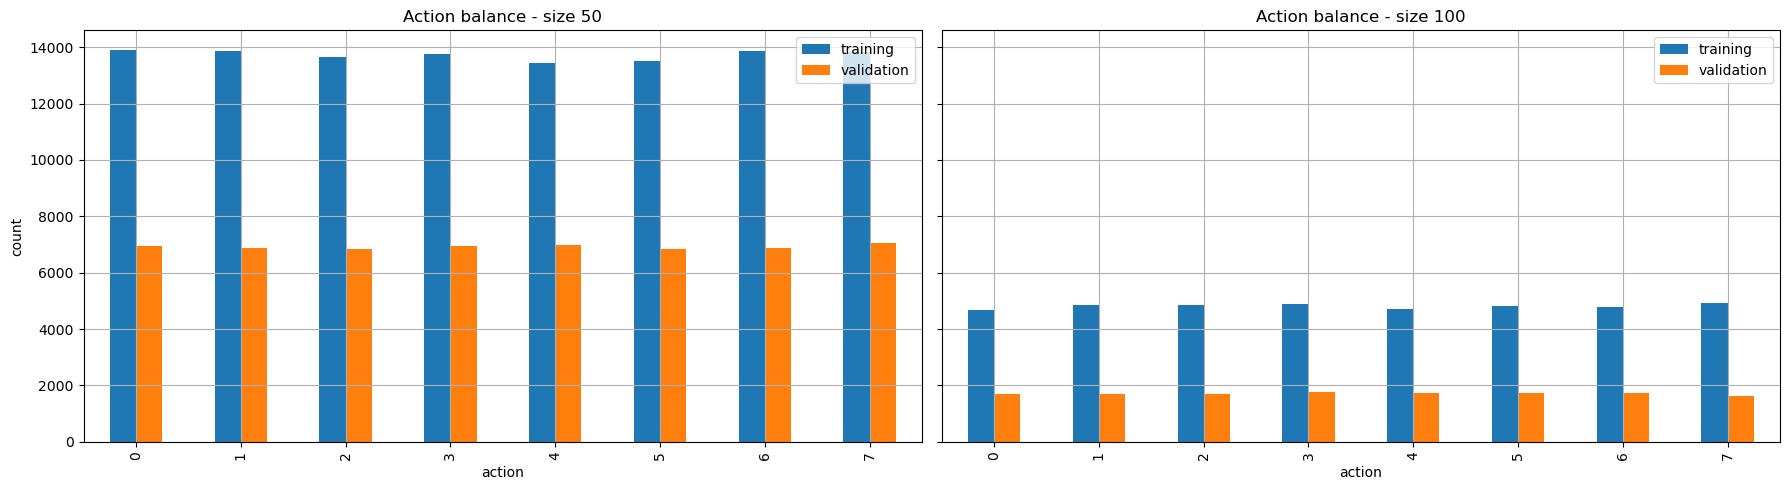

In [12]:
action_size = (
    pd.concat([
        train_df[["size", "action"]].assign(split="training"),
        val_df[["size", "action"]].assign(split="validation"),
    ], ignore_index=True)
    .groupby(["split", "size", "action"])
    .size()
    .reset_index(name="count")
)

display(action_size.head(20))

fig, axes = plt.subplots(1, len(sorted(action_size["size"].unique(), key=lambda x: int(x))), figsize=(18, 5), sharey=True)
sizes_sorted = sorted(action_size["size"].unique(), key=lambda x: int(x))
if len(sizes_sorted) == 1:
    axes = [axes]

for ax, size in zip(axes, sizes_sorted):
    sub = action_size[action_size["size"] == size]
    pivot = sub.pivot(index="action", columns="split", values="count").fillna(0)
    pivot.plot(kind="bar", ax=ax)
    ax.set_title(f"Action balance - size {size}")
    ax.set_xlabel("action")
    ax.set_ylabel("count")
    ax.legend()
plt.tight_layout()
plt.show()

## 6) Feature scale

We inspect the training feature scale first, because training statistics should later be used for normalization.

For each feature we compute:
- mean,
- standard deviation,
- minimum and maximum,
- quantiles,
- number of unique values,
- zero ratio.

This helps detect:
- dead or nearly constant features,
- scale mismatches,
- suspiciously large ranges.

In [13]:
def feature_summary(df: pd.DataFrame, feature_cols):
    rows = []
    for c in feature_cols:
        s = pd.to_numeric(df[c], errors="coerce")
        rows.append({
            "feature": c,
            "mean": s.mean(),
            "std": s.std(),
            "min": s.min(),
            "q01": s.quantile(0.01),
            "q05": s.quantile(0.05),
            "median": s.median(),
            "q95": s.quantile(0.95),
            "q99": s.quantile(0.99),
            "max": s.max(),
            "unique": s.nunique(dropna=True),
            "pct_zero": float((s == 0).mean()),
            "missing": int(s.isna().sum()),
        })
    out = pd.DataFrame(rows)
    out["abs_mean"] = out["mean"].abs()
    out["cv"] = out["std"] / (out["abs_mean"] + 1e-12)
    return out.sort_values("std", ascending=False)

train_feat_summary = feature_summary(train_df, FEATURE_COLS)
val_feat_summary = feature_summary(val_df, FEATURE_COLS)

display(train_feat_summary.head(15))
display(train_feat_summary.tail(15))

,feature,mean,std,min,q01,q05,median,q95,q99,max,unique,pct_zero,missing,abs_mean,cv
33,delta_trend,1.352368e+07,3.672689e+09,-1.000000,-0.999896,-0.895226,-0.061580,9.493864,1.583604e+04,9.999768e+11,129221,0.001511,0,1.352368e+07,271.574615
6,max_delta_W,2.481353e+05,1.990018e+06,0.000000,3.109272,6.071621,32.089073,415.020355,9.999150e+06,4.099910e+07,13906,0.000438,0,2.481353e+05,8.019892
5,avg_delta_W,1.522656e+04,1.147737e+05,0.000000,0.424332,0.930370,4.553498,79.258574,5.999870e+05,2.199979e+06,116680,0.000438,0,1.522656e+04,7.537733
19,horizon,1.084207e+03,1.012366e+03,230.000000,230.000000,230.000000,960.000000,3390.000000,3.390000e+03,3.390000e+03,6,0.000000,0,1.084207e+03,0.933739
21,avg_tw_width,3.413461e+02,3.852280e+02,34.117645,34.117645,59.980392,200.705887,785.455444,1.749177e+03,2.501465e+03,56,0.000000,0,3.413461e+02,1.128555
38,elapsed,3.049813e+02,2.207547e+02,0.000483,0.442701,6.374308,285.959534,703.674280,9.000000e+02,9.000000e+02,144431,0.000000,0,3.049813e+02,0.723830
22,min_tw_width,1.254839e+02,1.262472e+02,10.000000,10.000000,10.000000,79.000000,320.000000,6.400000e+02,6.400000e+02,27,0.000000,0,1.254839e+02,1.006083
10,PV,6.899608e+01,2.440408e+01,0.000000,43.000000,55.000000,55.000000,110.000000,1.100000e+02,1.100000e+02,68,0.000378,0,6.899608e+01,0.353702
17,n_customers,6.299397e+01,2.192848e+01,50.000000,50.000000,50.000000,50.000000,100.000000,1.000000e+02,1.000000e+02,2,0.000000,0,6.299397e+01,0.348104
0,gvns_iter,1.189235e+01,1.061837e+01,1.000000,1.000000,1.000000,9.000000,32.000000,3.400000e+01,3.600000e+01,36,0.000000,0,1.189235e+01,0.892873


,feature,mean,std,min,q01,q05,median,q95,q99,max,unique,pct_zero,missing,abs_mean,cv
31,waiting_time_ratio,3.782512e-01,2.382149e-01,0.000000,0.045476,0.078178,0.360988,0.716949,7.671686e-01,8.539137e-01,90933,0.000378,0,3.782512e-01,0.629780
25,late_tw_ratio,3.243596e-01,2.273284e-01,0.020000,0.020000,0.040000,0.260000,0.810000,8.600000e-01,8.600000e-01,43,0.000000,0,3.243596e-01,0.700853
4,improv_rate_W,6.211711e-01,2.000980e-01,0.000000,0.200000,0.300000,0.600000,1.000000,1.000000e+00,1.000000e+00,59,0.000378,0,6.211711e-01,0.322130
9,ls_fail_ratio_W,3.788290e-01,2.000980e-01,0.000000,0.000000,0.000000,0.400000,0.700000,8.000000e-01,1.000000e+00,59,0.122153,0,3.788290e-01,0.528201
23,tw_tightness,3.625294e-01,1.906504e-01,0.056631,0.058573,0.103362,0.379493,0.737895,7.860907e-01,7.860907e-01,55,0.000000,0,3.625294e-01,0.525890
24,early_tw_ratio,4.635141e-01,1.816075e-01,0.160000,0.160000,0.220000,0.420000,0.820000,8.400000e-01,8.400000e-01,38,0.000000,0,4.635141e-01,0.391806
15,k_norm,8.107948e-02,1.566865e-01,0.000000,0.000000,0.000000,0.000000,0.500000,7.500000e-01,8.750000e-01,8,0.624996,0,8.107948e-02,1.932505
29,tw_violation_ratio,4.872008e-02,9.167194e-02,0.000000,0.000000,0.000000,0.000000,0.236364,4.363636e-01,8.909091e-01,88,0.557482,0,4.872008e-02,1.881605
30,avg_lateness_norm,1.050468e-02,2.978677e-02,0.000000,0.000000,0.000000,0.000000,0.053171,1.461164e-01,5.232925e-01,22474,0.557482,0,1.050468e-02,2.835571
35,param_acceptance,5.318277e-02,1.509194e-02,0.006473,0.023047,0.030760,0.051832,0.079990,9.556215e-02,1.489262e-01,92290,0.000000,0,5.318277e-02,0.283775


In [14]:
zero_var = train_feat_summary[train_feat_summary["std"].fillna(0) <= ZERO_VAR_STD]["feature"].tolist()
near_zero_var = train_feat_summary[train_feat_summary["std"].fillna(0) <= NEAR_ZERO_VAR_STD]["feature"].tolist()

print("Zero-variance features:", zero_var)
print("Near-zero-variance features:", near_zero_var)

Zero-variance features: ['avg_delta_W_norm', 'sync_ratio', 'max_delta_W_norm', 'n_vehicles']
Near-zero-variance features: ['penS_ratio', 'avg_delta_W_norm', 'sync_ratio', 'max_delta_W_norm', 'n_vehicles']


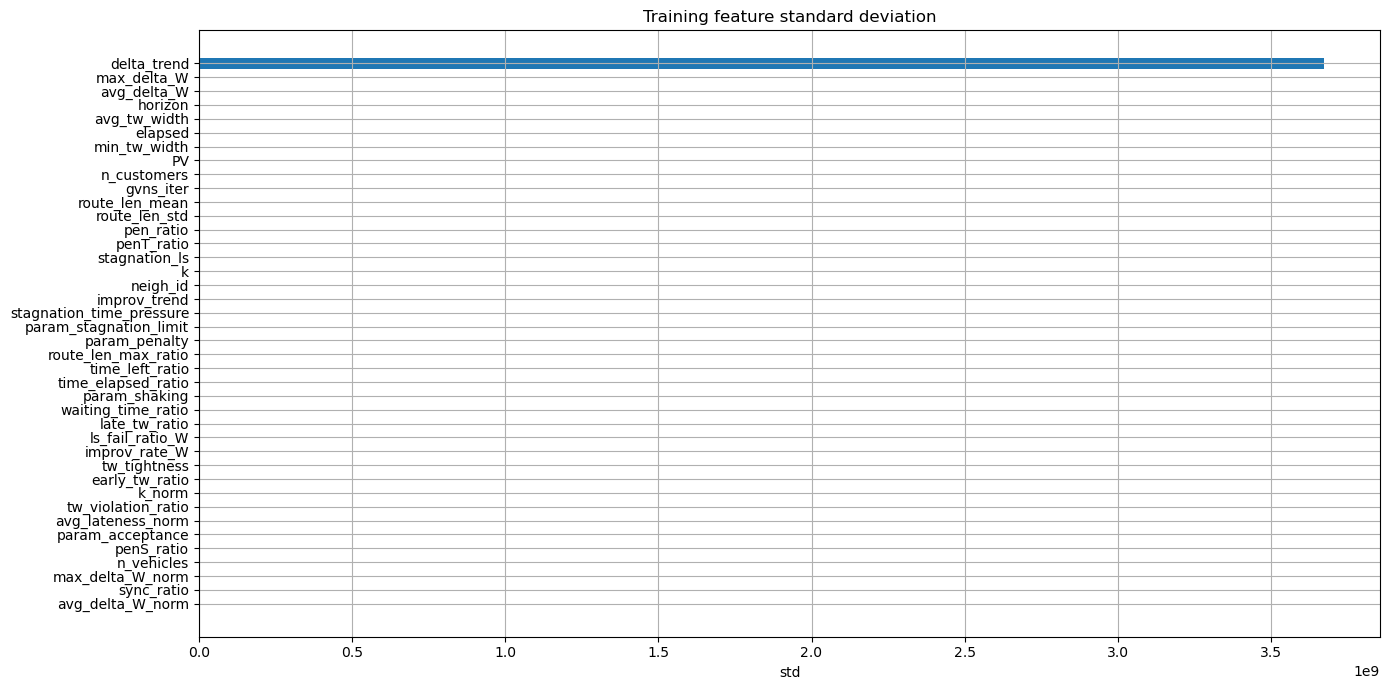

In [15]:
fig, ax = plt.subplots(figsize=(14, 7))
ordered = train_feat_summary.sort_values("std", ascending=True)
ax.barh(ordered["feature"], ordered["std"])
ax.set_title("Training feature standard deviation")
ax.set_xlabel("std")
plt.tight_layout()
plt.show()

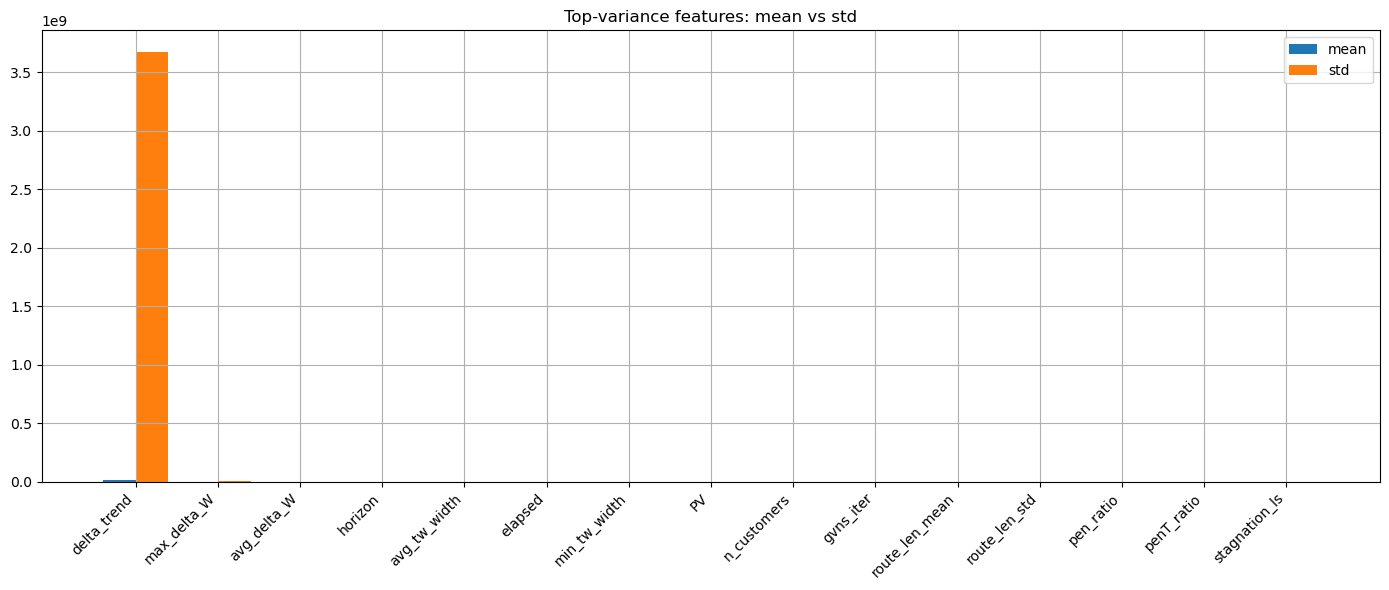

In [16]:
topn = 15
top_features = train_feat_summary.sort_values("std", ascending=False).head(topn)["feature"].tolist()
plot_df = train_feat_summary.set_index("feature").loc[top_features][["mean", "std"]]

fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(plot_df))
ax.bar(x - 0.2, plot_df["mean"].values, width=0.4, label="mean")
ax.bar(x + 0.2, plot_df["std"].values, width=0.4, label="std")
ax.set_xticks(x)
ax.set_xticklabels(plot_df.index, rotation=45, ha="right")
ax.set_title("Top-variance features: mean vs std")
ax.legend()
plt.tight_layout()
plt.show()

## 7) Feature correlations

We use Pearson correlation on the training set only.

This is important because:
- it identifies redundant features,
- it reveals whether some features are deterministic transforms of others,
- it helps us decide if some dimensions can be removed before training.

We inspect:
- the full correlation heatmap,
- the strongest absolute pairwise correlations,
- pairs above a redundancy threshold.

In [17]:
train_corr = train_df[FEATURE_COLS].corr(method="pearson")

corr_pairs = []
for i, a in enumerate(FEATURE_COLS):
    for j, b in enumerate(FEATURE_COLS):
        if j <= i:
            continue
        val = float(train_corr.loc[a, b])
        corr_pairs.append((a, b, val, abs(val)))

corr_pairs_df = pd.DataFrame(corr_pairs, columns=["feature_a", "feature_b", "corr", "abs_corr"])
corr_pairs_df = corr_pairs_df.sort_values("abs_corr", ascending=False)

display(corr_pairs_df.head(30))

,feature_a,feature_b,corr,abs_corr
77,time_elapsed_ratio,time_left_ratio,-1.000000,1.000000
455,k,k_norm,1.000000,1.000000
503,k_norm,neigh_id,1.000000,1.000000
479,k,neigh_id,1.000000,1.000000
154,improv_rate_W,ls_fail_ratio_W,-1.000000,1.000000
374,pen_ratio,penT_ratio,0.998812,0.998812
351,PV,n_customers,0.992711,0.992711
185,avg_delta_W,max_delta_W,0.977361,0.977361
112,time_elapsed_ratio,elapsed,0.951156,0.951156
148,time_left_ratio,elapsed,-0.951156,0.951156


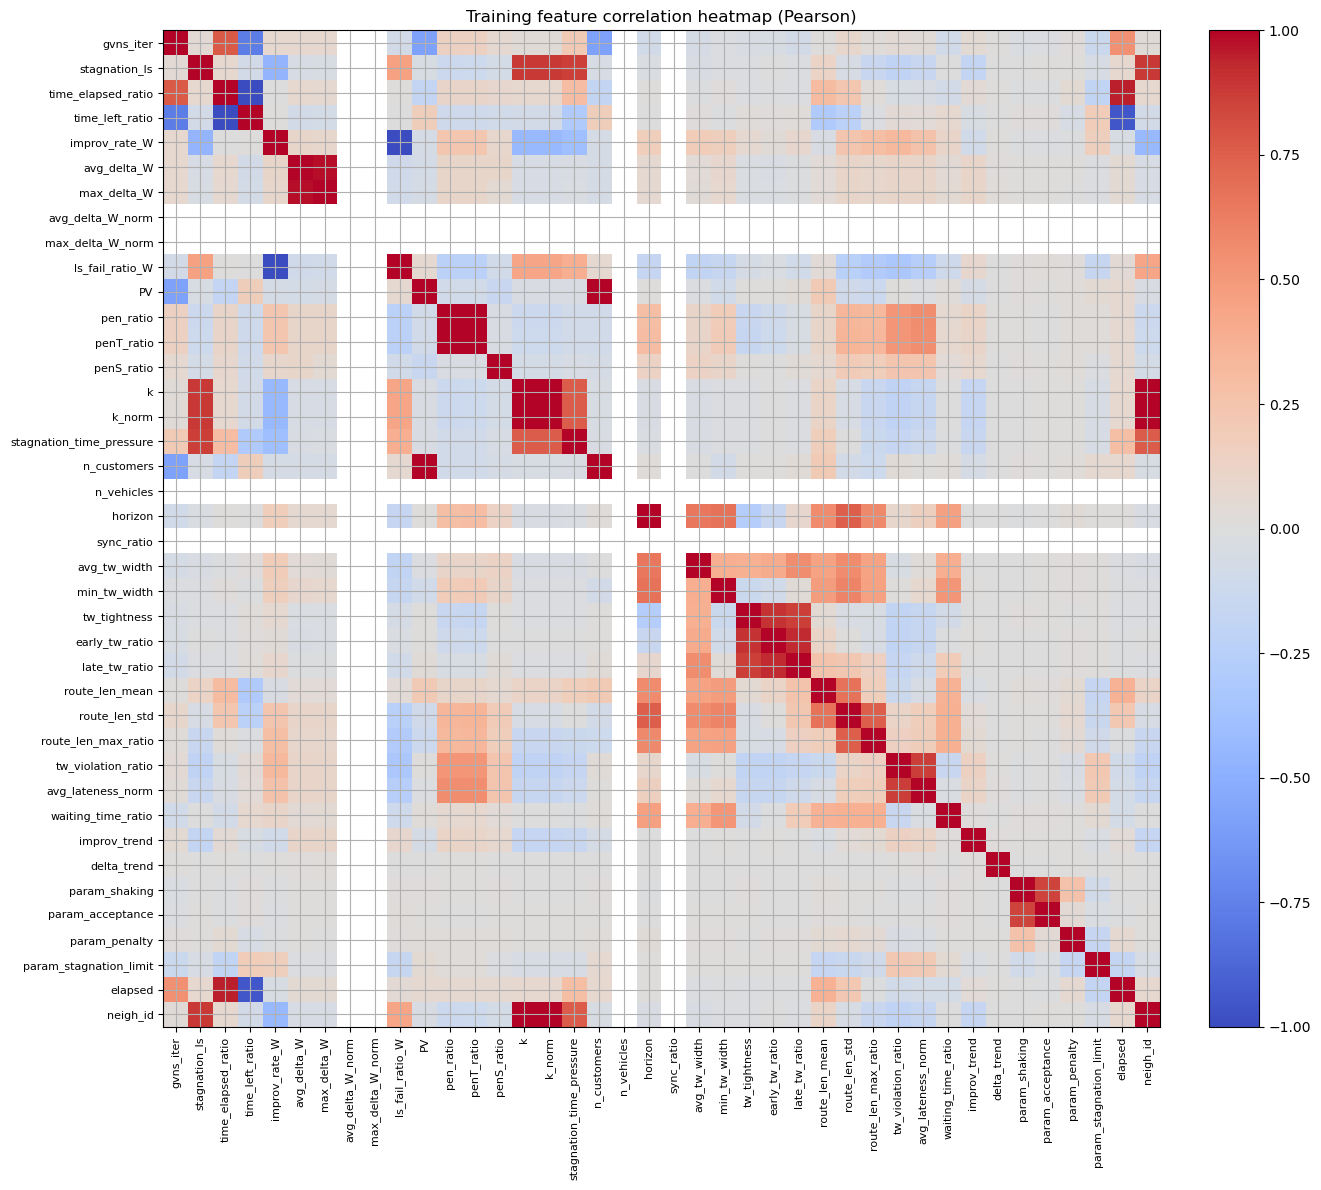

In [18]:
fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(train_corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(np.arange(len(FEATURE_COLS)))
ax.set_yticks(np.arange(len(FEATURE_COLS)))
ax.set_xticklabels(FEATURE_COLS, rotation=90, fontsize=8)
ax.set_yticklabels(FEATURE_COLS, fontsize=8)
ax.set_title("Training feature correlation heatmap (Pearson)")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

In [19]:
high_corr = corr_pairs_df[corr_pairs_df["abs_corr"] >= HIGH_CORR_THRESHOLD]
strong_corr = corr_pairs_df[corr_pairs_df["abs_corr"] >= STRONG_CORR_THRESHOLD]

print(f"Pairs with |corr| >= {HIGH_CORR_THRESHOLD}: {len(high_corr)}")
display(high_corr)

print(f"Pairs with |corr| >= {STRONG_CORR_THRESHOLD}: {len(strong_corr)}")
display(strong_corr.head(50))

Pairs with |corr| >= 0.95: 10


,feature_a,feature_b,corr,abs_corr
77,time_elapsed_ratio,time_left_ratio,-1.000000,1.000000
455,k,k_norm,1.000000,1.000000
503,k_norm,neigh_id,1.000000,1.000000
479,k,neigh_id,1.000000,1.000000
154,improv_rate_W,ls_fail_ratio_W,-1.000000,1.000000
374,pen_ratio,penT_ratio,0.998812,0.998812
351,PV,n_customers,0.992711,0.992711
185,avg_delta_W,max_delta_W,0.977361,0.977361
112,time_elapsed_ratio,elapsed,0.951156,0.951156
148,time_left_ratio,elapsed,-0.951156,0.951156


Pairs with |corr| >= 0.85: 18


,feature_a,feature_b,corr,abs_corr
77,time_elapsed_ratio,time_left_ratio,-1.000000,1.000000
455,k,k_norm,1.000000,1.000000
503,k_norm,neigh_id,1.000000,1.000000
479,k,neigh_id,1.000000,1.000000
154,improv_rate_W,ls_fail_ratio_W,-1.000000,1.000000
374,pen_ratio,penT_ratio,0.998812,0.998812
351,PV,n_customers,0.992711,0.992711
185,avg_delta_W,max_delta_W,0.977361,0.977361
112,time_elapsed_ratio,elapsed,0.951156,0.951156
148,time_left_ratio,elapsed,-0.951156,0.951156


## 8) Redundant or dead feature shortlist

A feature is flagged if it is:

- constant or almost constant,
- very low variance,
- present only in a tiny number of distinct values,
- or strongly redundant with another feature.

These are not automatically removed. The notebook just prepares the shortlist so we can decide before training.

In [20]:
dead_features = train_feat_summary[
    (train_feat_summary["std"].fillna(0) <= ZERO_VAR_STD) |
    (train_feat_summary["unique"] <= 1)
]["feature"].tolist()

low_information_features = train_feat_summary[
    (train_feat_summary["std"].fillna(0) <= NEAR_ZERO_VAR_STD) |
    (train_feat_summary["unique"] <= 3) |
    (train_feat_summary["pct_zero"] >= 0.99)
]["feature"].tolist()

redundant_features = sorted(set(
    corr_pairs_df.loc[corr_pairs_df["abs_corr"] >= HIGH_CORR_THRESHOLD, "feature_a"].tolist() +
    corr_pairs_df.loc[corr_pairs_df["abs_corr"] >= HIGH_CORR_THRESHOLD, "feature_b"].tolist()
))

print("Dead features shortlist:")
print(dead_features)

print("\nLow-information features shortlist:")
print(low_information_features)

print("\nPotentially redundant features shortlist:")
print(redundant_features)

Dead features shortlist:
['avg_delta_W_norm', 'sync_ratio', 'max_delta_W_norm', 'n_vehicles']

Low-information features shortlist:
['n_customers', 'penS_ratio', 'avg_delta_W_norm', 'sync_ratio', 'max_delta_W_norm', 'n_vehicles']

Potentially redundant features shortlist:
['PV', 'avg_delta_W', 'elapsed', 'improv_rate_W', 'k', 'k_norm', 'ls_fail_ratio_W', 'max_delta_W', 'n_customers', 'neigh_id', 'penT_ratio', 'pen_ratio', 'time_elapsed_ratio', 'time_left_ratio']


## 9) Next-state sanity check

It is useful to inspect how much the state changes from one transition to the next.

This catches:
- accidental logging bugs,
- transitions that repeat the same state too often,
- a controller that has no effect.

We compute:
- mean absolute transition delta,
- median absolute transition delta,
- proportion of transitions with almost no change.

In [21]:
def transition_delta_stats(df: pd.DataFrame, feature_cols):
    cur = df[feature_cols].to_numpy(dtype=np.float64)
    nxt = df[[f"next_{c}" for c in feature_cols]].to_numpy(dtype=np.float64)
    delta = np.abs(nxt - cur)
    per_row = delta.mean(axis=1)
    print("Mean abs delta per transition:", float(per_row.mean()))
    print("Median abs delta per transition:", float(np.median(per_row)))
    print("Zero-change transitions:", float((per_row <= 1e-12).mean()))
    return per_row

train_delta = transition_delta_stats(train_df, FEATURE_COLS)
val_delta = transition_delta_stats(val_df, FEATURE_COLS)

Mean abs delta per transition: 338586.8368874965
Median abs delta per transition: 0.06267207665368915
Zero-change transitions: 0.0
Mean abs delta per transition: 873826.5790320992
Median abs delta per transition: 0.060727452859282494
Zero-change transitions: 0.0


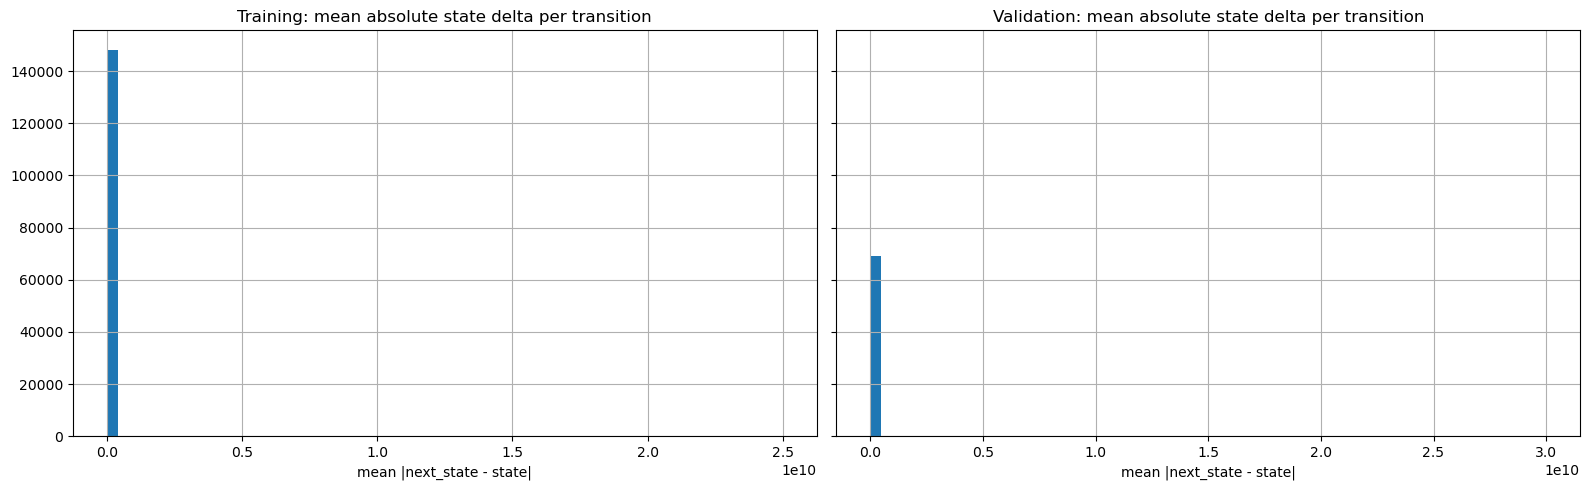

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
axes[0].hist(train_delta, bins=60)
axes[0].set_title("Training: mean absolute state delta per transition")
axes[0].set_xlabel("mean |next_state - state|")

axes[1].hist(val_delta, bins=60)
axes[1].set_title("Validation: mean absolute state delta per transition")
axes[1].set_xlabel("mean |next_state - state|")

plt.tight_layout()
plt.show()

## 10) Per-instance and per-run summaries

We now group by:
- split,
- size,
- instance,
- run.

This gives a much better picture than a single global average. It lets us check whether some instances are unusually noisy, unusually flat, or have no useful learning signal.

In [23]:
def instance_run_summary(df: pd.DataFrame):
    rows = []
    max_action = int(df["action"].max())

    for (split, size, instance, run_id), g in df.groupby(["split", "size", "instance", "run_id"], dropna=False):
        rewards = g["reward"].to_numpy()
        acts = g["action"].to_numpy().astype(int)
        counts = np.bincount(acts, minlength=max_action + 1)
        p = counts / counts.sum()
        ent = float(-(np.where(p > 0, p * np.log(p), 0.0)).sum())

        rows.append({
            "split": split,
            "size": size,
            "instance": instance,
            "run_id": run_id,
            "transitions": len(g),
            "reward_mean": rewards.mean(),
            "reward_std": rewards.std(),
            "reward_min": rewards.min(),
            "reward_max": rewards.max(),
            "action_entropy": ent,
            "done_ratio": g["done"].mean(),
            "mean_abs_state_delta": float(
                np.mean(np.abs(
                    g[[f"next_{c}" for c in FEATURE_COLS]].to_numpy(dtype=np.float64) -
                    g[FEATURE_COLS].to_numpy(dtype=np.float64)
                ))
            ),
        })
    return pd.DataFrame(rows)

run_summary_df = instance_run_summary(pd.concat([train_df, val_df], ignore_index=True))
display(run_summary_df.head(20))

,split,size,instance,run_id,transitions,reward_mean,reward_std,reward_min,reward_max,action_entropy,done_ratio,mean_abs_state_delta
0,training,100,C101_100_10,1,1335,0.057182,0.114252,-0.166573,0.831201,2.075620,0.0,0.278522
1,training,100,C105_100_10,1,1339,0.059606,0.116831,-0.181372,0.633063,2.072847,0.0,0.332474
2,training,100,C106_100_10,1,1278,0.066350,0.119660,-0.156441,1.000000,2.074919,0.0,1080.255543
3,training,100,C108_100_10,1,1301,0.079261,0.114604,-0.120991,0.909432,2.076924,0.0,0.328111
4,training,100,C201_100_10,1,1160,0.078562,0.135162,-0.108187,1.000000,2.077163,0.0,1099.662755
5,training,100,C204_100_10,1,1240,0.079223,0.109324,-0.050000,0.771968,2.078931,0.0,0.200015
6,training,100,C205_100_10,1,1458,0.100878,0.137284,-0.050000,0.960617,2.076177,0.0,0.564649
7,training,100,C207_100_10,1,1613,0.102199,0.126281,-0.050000,1.000000,2.075784,0.0,3825.602734
8,training,100,R103_100_10,1,1289,0.053354,0.098021,-0.060775,0.272293,2.077285,0.0,0.129761
9,training,100,R104_100_10,1,1488,0.056362,0.100208,-0.102499,0.442377,2.077593,0.0,0.134937


In [24]:
summary_by_size = (
    run_summary_df.groupby(["split", "size"])
    .agg({
        "transitions": ["count", "mean", "std", "min", "max"],
        "reward_mean": ["mean", "std", "min", "max"],
        "reward_std": ["mean", "std"],
        "action_entropy": ["mean", "std"],
        "mean_abs_state_delta": ["mean", "std"],
    })
)
display(summary_by_size)

transitions                                      reward_mean  \
                      count         mean         std   min   max        mean   
split      size                                                                
training   100           28  1376.107143  139.645938  1130  1683    0.069043   
           50            28  3919.071429  393.730866  3246  4683    0.075525   
validation 100           10  1365.700000  208.727920  1145  1686    0.062806   
           50            10  5534.000000  451.050379  4756  6511    0.066173   

                                              reward_std            \
                      std       min       max       mean       std   
split      size                                                      
training   100   0.013330  0.044014  0.102199   0.107261  0.011348   
           50    0.021526  0.044720  0.124100   0.122940  0.016487   
validation 100   0.014364  0.043310  0.086728   0.106482  0.010140   
           50    0.022876  0.028533  0.094785   0.118211  0.015853   

                action_entropy           mean_abs_state_delta                
                          mean       std                 mean           std  
split      size                                                              
training   100        2.076901  0.001342         3.590617e+02  8.020138e+02  
           50         2.078435  0.000496         4.180599e+05  2.202760e+06  
validation 100        2.076395  0.001360         7.256965e+03  2.126700e+04  
           50         2.078860  0.000317         1.090379e+06  3.435768e+06

## 11) Save diagnostic tables

These CSVs will be useful later when writing the final report and when deciding whether any feature should be removed before training.

In [25]:
output_dir = Path("gvns/rl/notebooks/evaluation_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

train_feat_summary.to_csv(output_dir / "train_feature_summary.csv", index=False)
val_feat_summary.to_csv(output_dir / "val_feature_summary.csv", index=False)
corr_pairs_df.to_csv(output_dir / "train_correlation_pairs.csv", index=False)
train_file_summary.to_csv(output_dir / "train_file_summary.csv", index=False)
val_file_summary.to_csv(output_dir / "val_file_summary.csv", index=False)
run_summary_df.to_csv(output_dir / "run_summary.csv", index=False)
reward_split_summary.to_csv(output_dir / "reward_split_summary.csv", index=False)
reward_by_size.to_csv(output_dir / "reward_by_size.csv", index=False)

print(f"Saved diagnostics to: {output_dir}")

Saved diagnostics to: gvns\rl\notebooks\evaluation_outputs


## 12) What to decide before training

After running this notebook, the next decisions are:

1. whether the reward scale is good enough,
2. whether any feature should be removed,
3. whether the training and validation splits are sufficiently different,
4. whether normalization should be fitted on training only,
5. whether the PPO controller can train on the current feature set without pruning.